# Paired PD–Booth comparison at matched acquisition budgets

Compare the **completed cumulative PD RMS–SNR and RMS–bead-count sweeps** with three-point modal brightness correction (the repository's Booth implementation). Reuse archived PD trajectories; simulate new closed-loop Booth trajectories. Each paired case shares its sample, initial wavefront, optics, modes, fixed exposure, gain, and modal update limits. Each method acquires images under its own evolving correction; later signals and SNRs can differ.

Budgets are **36, 72, 108 frames**. PD applies updates at those counts. Single-plane Booth measures at predetermined z=0: one baseline plus ±bias per each of 17 modes, costing **35 frames per update** (35, 70, 105 frames). Compare the last committed correction within each budget. No selection by ground-truth performance. This does not compare equal loop cost or equal detected photons.

Booth bias is fixed at **0.10 coefficient waves**, using the existing implementation's default study setting; it has not been tuned on these test cases. All modal commands remain fixed during probing and are updated together; flat/convex parabolas use the best measured bias. This is an implementation-specific baseline, not a claim about all sensorless AO variants. Fixed z=0 may disadvantage samples with predominantly out-of-focus signal. Four-plane Booth (140 images/update) is outside this 108-image comparison.

Three independent wavefront directions are shared across the axes. Bead geometries are reconstructed from saved centers and radii, including overlaps. Exposure was calibrated separately per case to the initial aberrated z=0 image. Thus matching exposure is within each paired case, not across sweep points. Reported success counts are descriptive, not precise population probabilities.

In [1]:
from pathlib import Path
import sys, json, hashlib, time, os, tempfile
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
ROOT = Path.cwd()
while not ((ROOT / 'utils').is_dir() and (ROOT / 'optimization').is_dir()):
    if ROOT == ROOT.parent:
        raise RuntimeError('Run this notebook inside the repository.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from utils import psf, zernike
from systematic_testing import correction
EXPERIMENT_DIR = ROOT / 'systematic_testing/correction_comparison'
RESULTS_DIR = EXPERIMENT_DIR / 'results/paired_sweeps'
FIGURES_DIR = EXPERIMENT_DIR / 'figures/paired_sweeps'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use('bmh')
plt.rcParams.update({'font.size': 10, 'text.usetex': True, 'figure.dpi': 150})
BUDGETS = np.array([36, 72, 108])
BOOTH_BIAS = 0.10
BOOTH_NOISE_SEED = 20261012
WORKERS = 2  # Independent simulator per case; use 1 to reduce CPU load.
RUN_BOOTH = False  # Reload saved results; True runs any unfinished Booth cases.
SOURCES = {
 'rms_snr': ROOT / 'systematic_testing/rms_snr_sweep/results/pd_rms_snr_sweep_random100_cumulative_scheduleddiversities_aberrated_z0_snr_rms030.npz',
 'bead_count': ROOT / 'systematic_testing/bead_count_sweep/results/pd_rms_bead_count_sweep_snr15_results.npz',
}

## Archive checks and case matching

Before running Booth, require complete PD archives and verify that every archived update occurs at the declared budgets. A fresh initial zero-diversity simulation checks both wavefront RMS and reference-SNR calibration for every case. This detects mismatches in geometry, exposure, and optical settings.

Independent seeded noise is used for Booth, with a reproducible seed per case. Random generators are never shared between workers. Checkpoints save all results after each completed trajectory; rerunning skips completed cases and checks source hashes and experiment settings. An interrupted unfinished trajectory is replayed from its seed, not from an approximate state.

In [2]:
def new_microscope():
    return psf.Microscope(N_order=3, lambd=1.3e-3, n=1.333, num_apt=1.05,
                         f=7.2, mag=4, w_0=3.5, L_bfp=15.12, grid_bfp=32)

def read_archive(path):
    with path.open('rb') as stream:
        with np.load(stream, allow_pickle=False) as archive:
            return {key: archive[key].copy() for key in archive.files}

archives = {name: read_archive(path) for name, path in SOURCES.items()}
for name, d in archives.items():
    assert d['completed'].all(), f'{name}: incomplete PD sweep'
    assert np.isfinite(d['residual_rms']).all()
    assert np.array_equal(d['images_taken'], np.broadcast_to(BUDGETS, d['images_taken'].shape))
    assert len(d['modes']) == 17
    assert str(d['snr_calibration']) == 'initial_aberrated_z0_no_diversity_fixed_exposure'
    print(f"{name}: {d['completed'].shape[:-1]}, {d['completed'].all(-1).sum()} paired trajectories")

booth_source_hash = hashlib.sha256((ROOT / 'systematic_testing/correction.py').read_bytes()).hexdigest()
psf_source_hash = hashlib.sha256((ROOT / 'utils/psf.py').read_bytes()).hexdigest()

def configuration(name, d):
    return json.dumps(dict(source=str(SOURCES[name]),
        source_sha256=hashlib.sha256(SOURCES[name].read_bytes()).hexdigest(),
        correction_sha256=booth_source_hash, psf_sha256=psf_source_hash,
        budgets=BUDGETS.tolist(), booth_bias=BOOTH_BIAS, booth_focal_positions=[0.0],
        booth_metric='mean_brightness', booth_noise_seed=BOOTH_NOISE_SEED,
        optical_mode='vector', gain=float(d['correction_gain']),
        max_modal_update=float(d['max_modal_update']),
        snr_calibration=str(d['snr_calibration'])), sort_keys=True)

def empty_results(name, d):
    shape = d['residual_rms'].shape
    modes_count = len(d['modes'])
    return dict(configuration=np.array(configuration(name, d)),
        completed=np.zeros(shape[:-1], dtype=bool),
        pd_residual_rms=d['residual_rms'].copy(), booth_residual_rms=np.full(shape, np.nan),
        booth_slm_strengths=np.full(shape+(modes_count,), np.nan),
        booth_probe_metrics=np.full(shape+(modes_count,3), np.nan),
        booth_updates=np.full(shape+(modes_count,), np.nan),
        booth_used_parabola=np.zeros(shape+(modes_count,), dtype=bool),
        booth_photons_detected=np.zeros(shape, dtype=np.int64),
        booth_images_taken=np.zeros(shape, dtype=int),
        booth_seconds=np.full(shape[:-1], np.nan),
        reference_snr=np.full(shape[:-1], np.nan),
        initial_rms=d['initial_rms'].copy(),
        x_values=d['bead_counts'].copy() if name=='bead_count' else d['target_snr'].copy(),
        axis_names=np.array(['initial_rms', 'bead_count' if name=='bead_count' else 'target_snr', 'trial', 'budget']),
        budgets=BUDGETS.copy(), modes=d['modes'].copy(),
        truth_strengths=d['truth_strengths'].copy(), exposures=d['exposures'].copy(),
        pd_images_taken=d['images_taken'].copy(), pd_acquisition_snr=d['acquisition_snr'].copy(),
        pd_optimizer_steps=d['optimizer_steps'].copy())

def save_results(path, state):
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix='.npz', delete=False) as stream:
        temporary = Path(stream.name)
        np.savez_compressed(stream, **state)
    os.replace(temporary, path)

states = {}
for name, d in archives.items():
    path = RESULTS_DIR / f'{name}_pd_booth.npz'
    state = read_archive(path) if path.exists() else empty_results(name, d)
    assert str(state['configuration']) == configuration(name, d), 'Checkpoint configuration changed; use a new results directory.'
    states[name] = state
    print(name, 'Booth cases already saved:', int(state['completed'].sum()))

rms_snr: (6, 7, 3), 126 paired trajectories
bead_count: (6, 5, 3), 90 paired trajectories
rms_snr Booth cases already saved: 126
bead_count Booth cases already saved: 90


In [3]:
def make_sample(name, d, ci, trial):
    grid = psf.Centered_Square_Grid(L_ffp=0.0065, grid_ffp=32, z_level=0)
    if name == 'bead_count':
        count = int(d['bead_counts'][ci])
        centers = d['bead_positions_mm'][ci, trial, :count]
        assert np.isfinite(centers).all()
        radii = np.full(count, float(d['bead_radius_mm']))
    else:
        centers = np.zeros((1, 3))
        radii = np.array([0.001])
    return psf.bead_img_3D(grid, d['sample_z'], centers[:,0], centers[:,1], centers[:,2], radii)

def run_case(name, index):
    d = archives[name]
    ri, ci, trial = index
    microscope = new_microscope()
    sample = make_sample(name, d, ci, trial)
    truth = zernike.Aberration(d['modes'], d['truth_strengths'][ri, trial])
    exposure = float(d['exposures'][index])
    clean = microscope.compute_image_3D(sample, truth, [0.0], mode='vector')[3]
    signal = np.maximum(clean, 0) * exposure
    reference_snr = float(np.sqrt(np.sum(signal**2) / np.sum(signal)))
    target = float(d['target_snr']) if name=='bead_count' else float(d['target_snr'][ci])
    assert np.isclose(reference_snr, target, rtol=1e-9), f'Reference SNR mismatch: {reference_snr} != {target}'
    simulator = correction.SimulatedSLM(microscope, sample, truth, d['modes'], exposure,
        np.random.default_rng(np.random.SeedSequence([BOOTH_NOISE_SEED, 0 if name=='rms_snr' else 1, ri, ci, trial])))
    assert np.isclose(simulator.residual_rms(), d['initial_rms'][ri], rtol=1e-10)
    started = time.perf_counter()
    history = correction.booth_feedback(simulator, np.array([0.0]), BOOTH_BIAS,
        int(BUDGETS[-1]), gain=float(d['correction_gain']), max_update=float(d['max_modal_update']))
    seconds = time.perf_counter()-started
    counts = np.array([record['images_taken'] for record in history])
    indices = np.searchsorted(counts, BUDGETS, side='right')-1
    assert np.array_equal(counts[indices], [35,70,105])
    records = [history[i] for i in indices]
    return name, index, dict(
        booth_residual_rms=np.array([p['residual_rms'] for p in records]),
        booth_slm_strengths=np.array([p['slm_strengths'] for p in records]),
        booth_probe_metrics=np.array([p['probe_metrics'] for p in records]),
        booth_updates=np.array([p['update'] for p in records]),
        booth_used_parabola=np.array([p['used_parabola'] for p in records]),
        booth_photons_detected=np.array([p['photons_detected'] for p in records]),
        booth_images_taken=counts[indices], booth_seconds=seconds, reference_snr=reference_snr)

## Run the two paired sweeps

This cell runs **216 Booth trajectories**, each with three complete modal sweeps. It does not rerun PD, connect to existing notebook kernels, or modify the source archives. Two workers handle independent cases. Each completion checkpoints its results. Runtime excludes the initial diagnostic calibration image, which is not charged as an algorithm acquisition. PD runtime was not archived, so no wall-time superiority claim is made here.

In [4]:
if RUN_BOOTH:
    pending = [(name, index) for name, d in archives.items()
               for index in np.ndindex(d['residual_rms'].shape[:-1]) if not states[name]['completed'][index]]
    started = time.perf_counter()
    print(f'Running {len(pending)} pending trajectories with {WORKERS} workers.', flush=True)
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        futures = [pool.submit(run_case, name, index) for name, index in pending]
        for number, future in enumerate(as_completed(futures), 1):
            name, index, values = future.result()
            state = states[name]
            for key, value in values.items():
                state[key][index] = value
            state['completed'][index] = True
            save_results(RESULTS_DIR / f'{name}_pd_booth.npz', state)
            if number == 1 or number % 5 == 0 or number == len(pending):
                elapsed = time.perf_counter()-started
                print(f'{number}/{len(pending)} saved | {name} {index} | elapsed {elapsed/60:.1f} min | '
                      f'estimated remaining {(len(pending)-number)*elapsed/max(number,1)/60:.1f} min', flush=True)
for name, state in states.items():
    assert state['completed'].all(), f'{name}: pending Booth cases; enable RUN_BOOTH to finish.'
    assert np.isfinite(state['booth_residual_rms']).all()
    assert np.isfinite(state['booth_slm_strengths']).all()
    assert np.all(state['booth_images_taken'] <= BUDGETS)
    print(name, 'complete:', int(state['completed'].sum()), 'trajectories')

rms_snr complete: 126 trajectories
bead_count complete: 90 trajectories


## Grid maps matching the original PD sweeps

Rows show PD and Booth; columns show acquisition budgets. As in both original sweep notebooks, grid maps use equally spaced cells (`imshow`, origin lower), categorical SNR/count ticks, three-decimal numbers inside every cell, adaptive white/black text, and no contours or sample dots. The bmh style, 12-point base font, 13 × 4.8 inch sizing per row and narrow dedicated colorbar column also match the originals. The layout has two rows to accommodate both methods.

Absolute and relative RMS use viridis with shared scales across both methods and both sweep families. Paired differences use a symmetric diverging scale centered at zero; positive favors PD. The difference metric has no original PD-only equivalent, but uses the same grid layout and annotations. Round colorbar ticks are retained.

Collected photon counts are saved for Booth, but the PD archives lack detected-photon totals, so photon-efficiency plots are not constructed. Independent noise streams and only three trials limit uncertainty estimates.


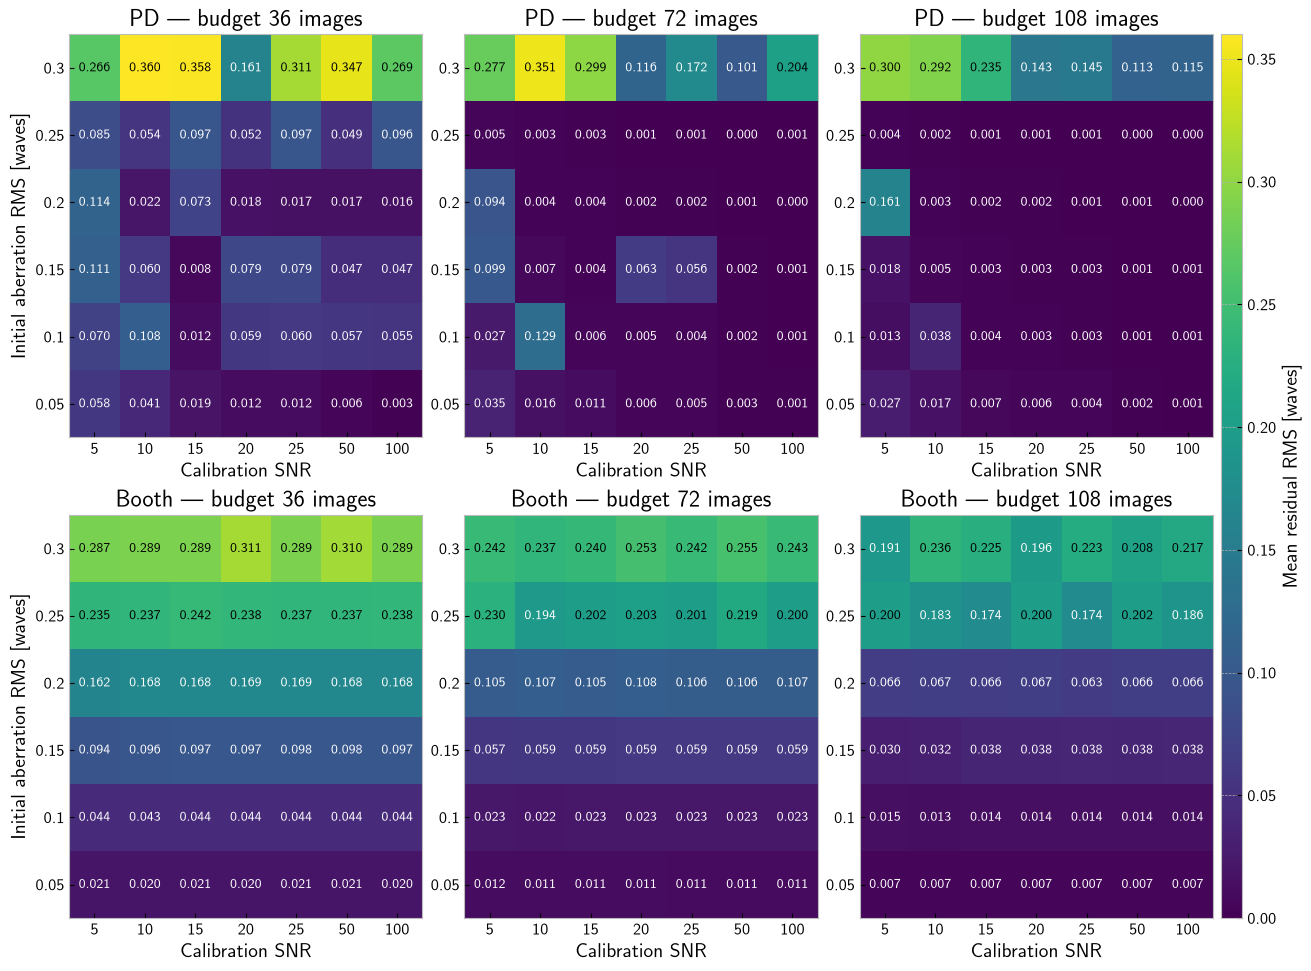

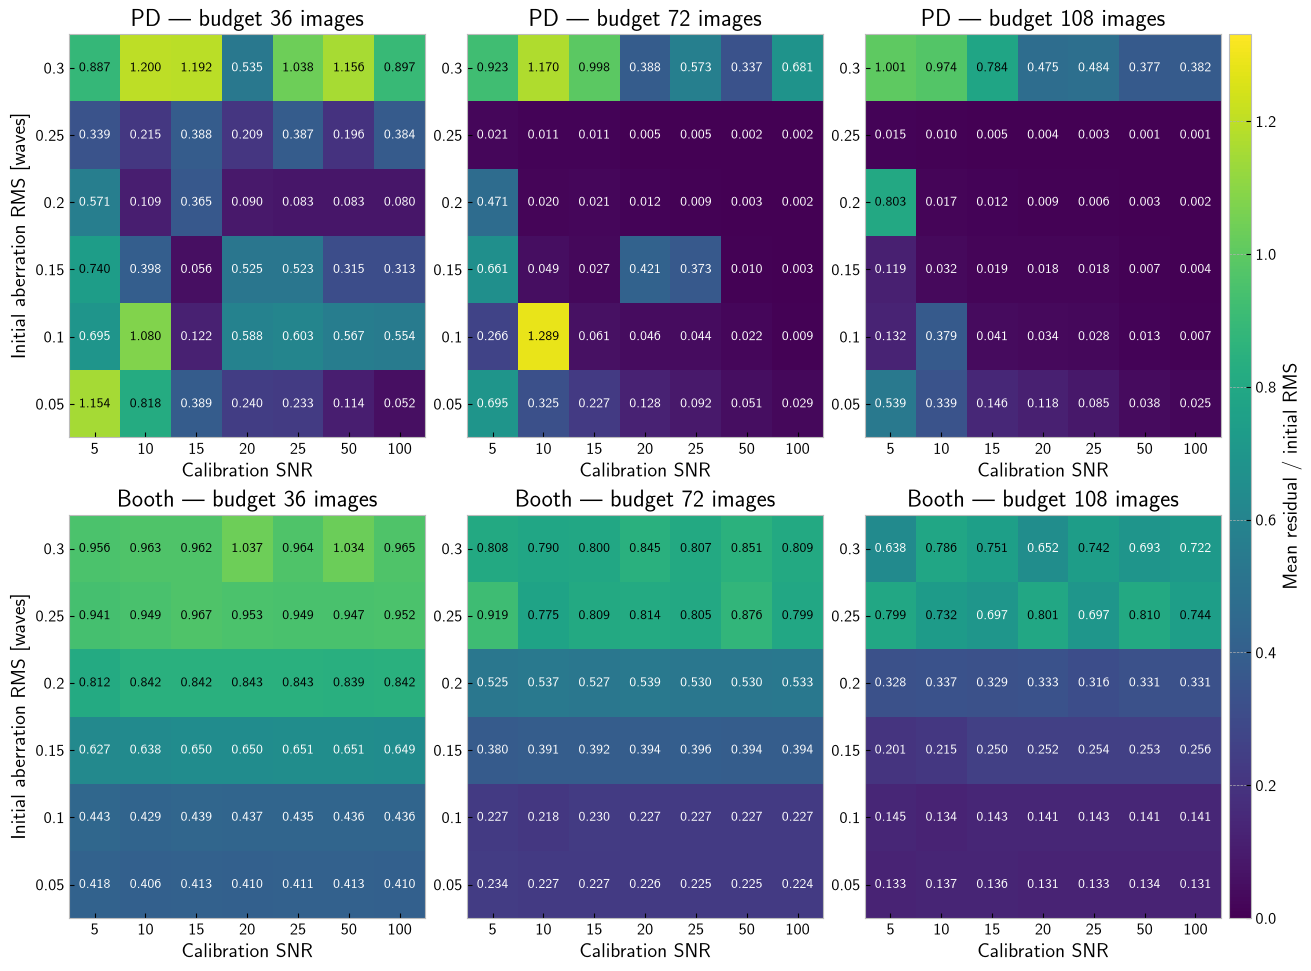

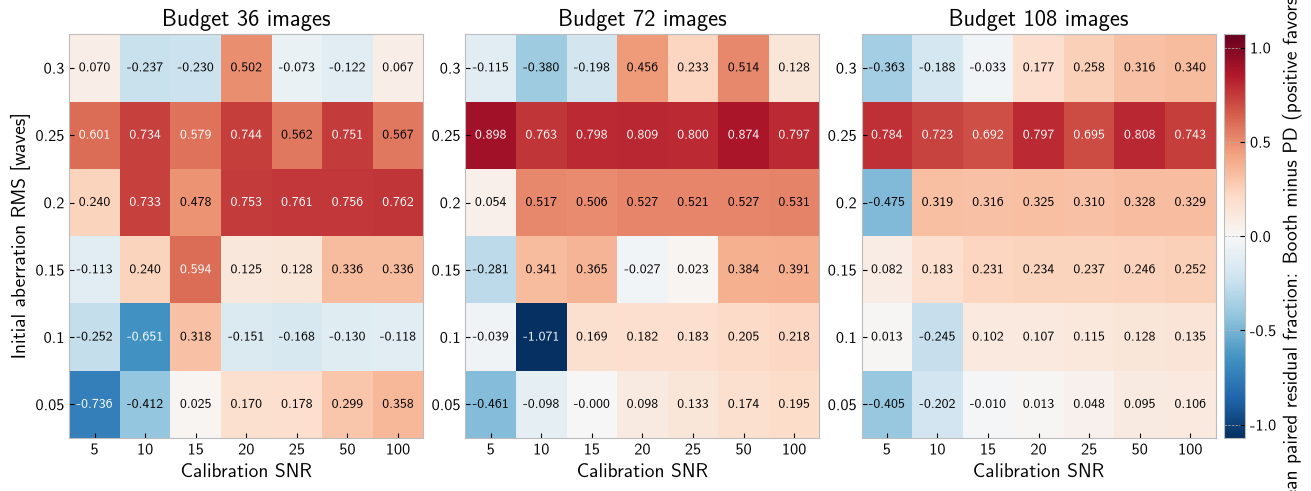

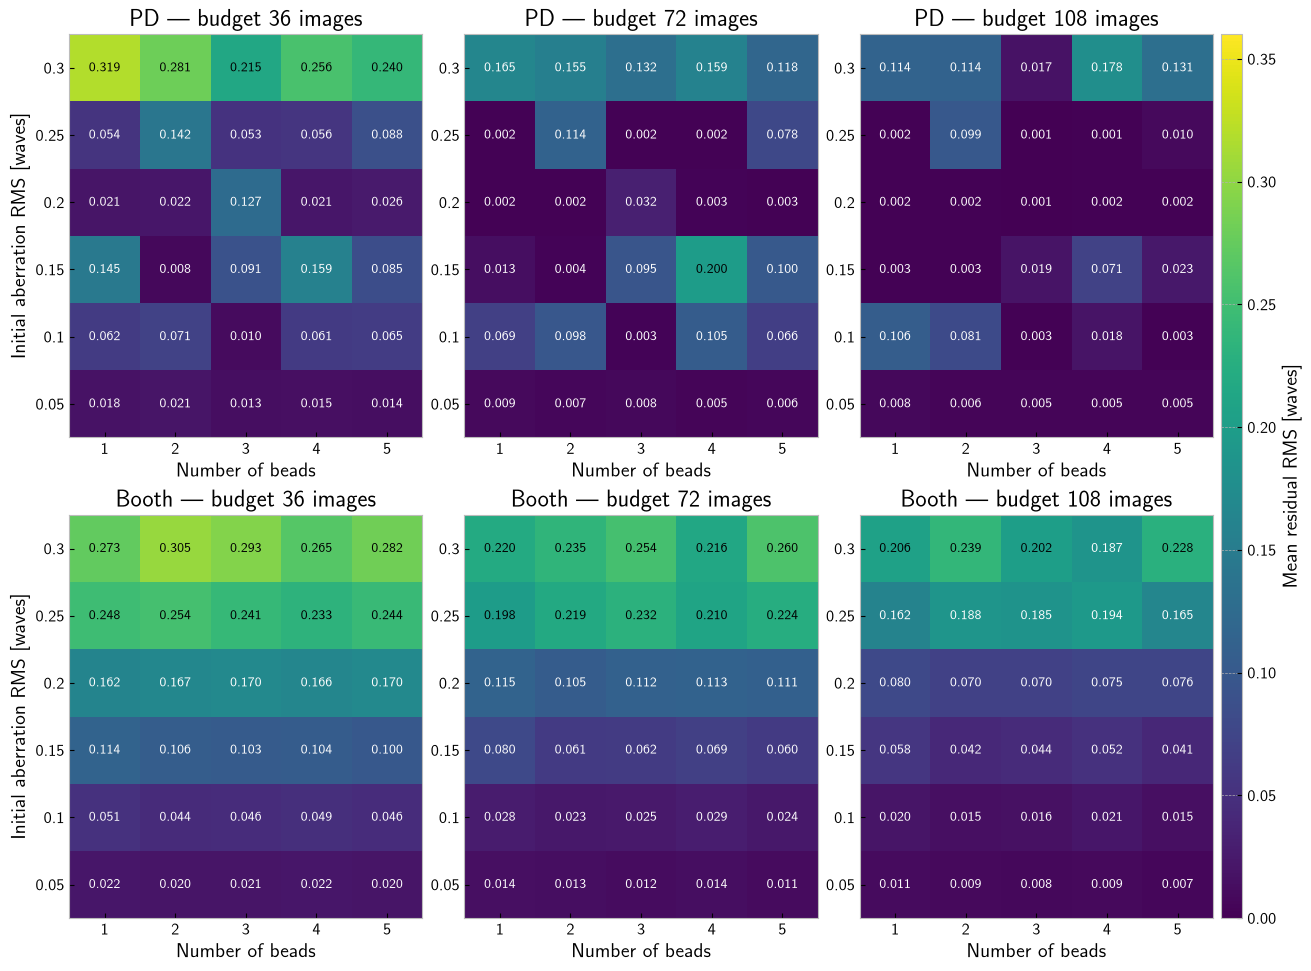

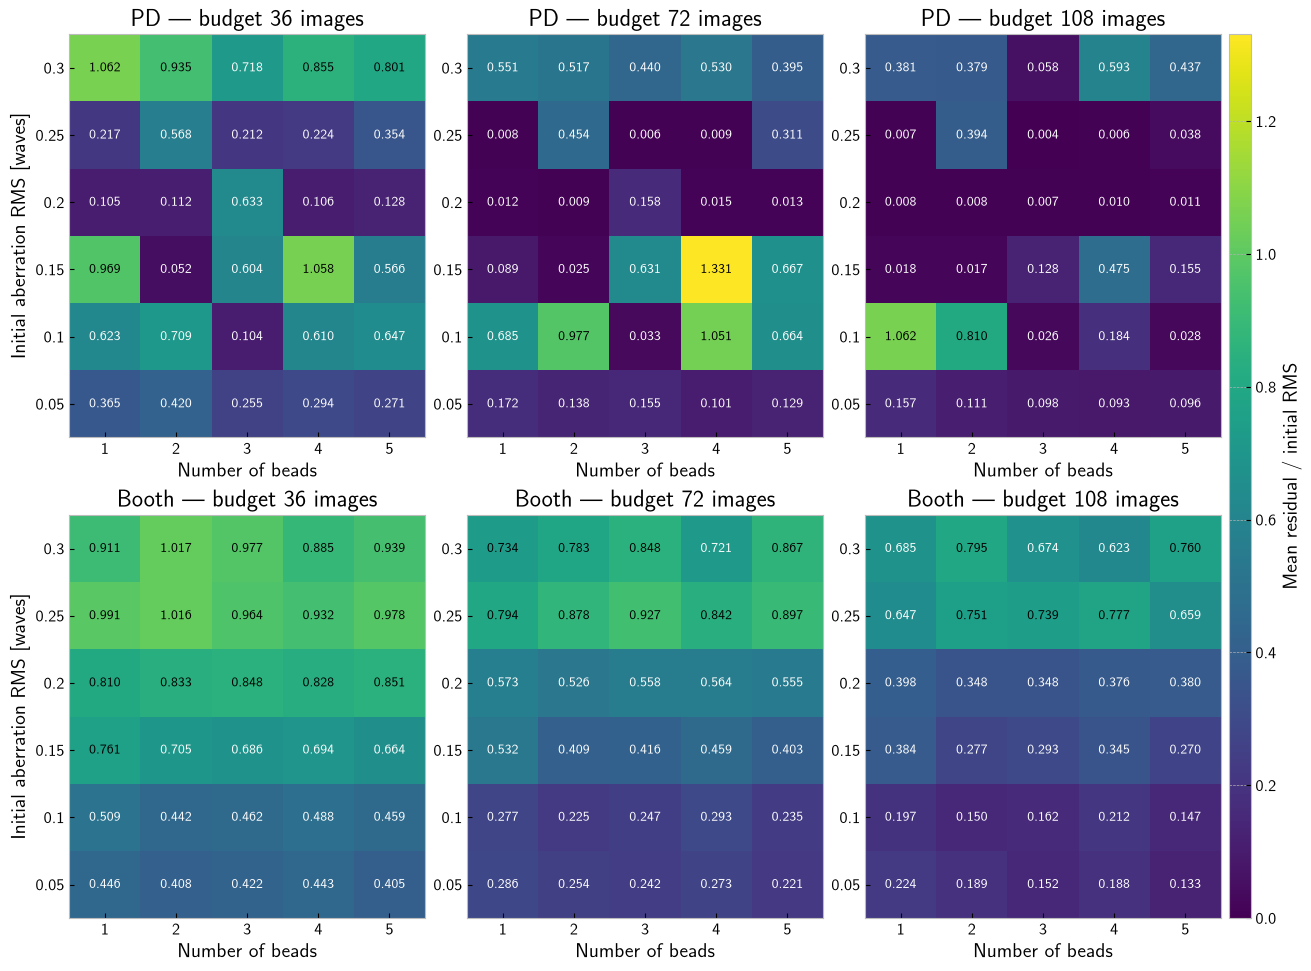

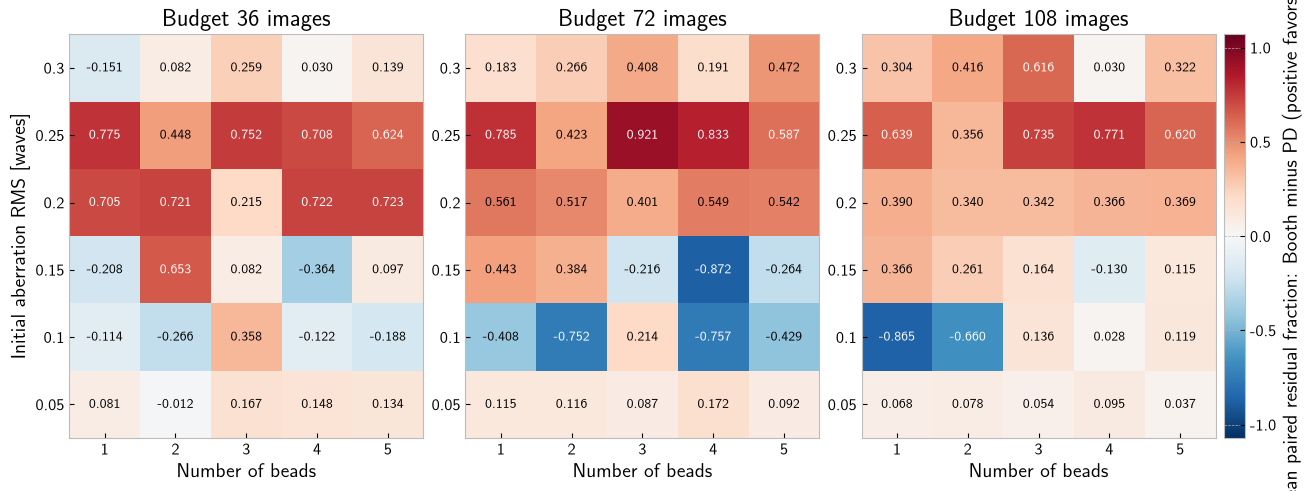

In [5]:
absolute_max = max(float(state[key].mean(axis=2).max()) for state in states.values()
                   for key in ('pd_residual_rms','booth_residual_rms'))
relative_max = max(float((state[key]/state['initial_rms'][:,None,None,None]).mean(axis=2).max())
                   for state in states.values() for key in ('pd_residual_rms','booth_residual_rms'))
difference_max = max(float(np.abs(((state['booth_residual_rms']-state['pd_residual_rms'])/
                    state['initial_rms'][:,None,None,None]).mean(axis=2)).max()) for state in states.values())

# Match both original PD sweep notebooks: bmh style, 12-point text,
# 13 x 4.8 inches per row and a narrow dedicated colorbar column.
plt.rcParams.update({'font.size': 12, 'text.usetex': True, 'figure.dpi': 150})

def save_figure(fig, stem):
    for ext in ('png','pdf'):
        fig.savefig(FIGURES_DIR / f'{stem}.{ext}', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def comparison_layout(rows):
    fig = plt.figure(figsize=(13, 4.8 * rows), dpi=150, layout='constrained')
    layout = fig.add_gridspec(rows, 4, width_ratios=[1,1,1,0.06])
    axes = np.array([[fig.add_subplot(layout[row,col]) for col in range(3)]
                     for row in range(rows)])
    colorbar_axis = fig.add_subplot(layout[:, -1])
    return fig, axes, colorbar_axis

def plot_panel(ax, name, state, values, norm, *, contour, difference=False, ratios=None):
    labels = state['x_values']
    y = state['initial_rms']
    cmap = 'RdBu_r' if difference else 'viridis'
    if contour:
        x = np.log10(labels) if name=='rms_snr' else labels
        levels = np.linspace(norm.vmin, norm.vmax, 21)
        im = ax.contourf(x, y, values, levels=levels, norm=norm, cmap=cmap)
        if ratios is not None and ratios.min() < 1 < ratios.max():
            boundary = ax.contour(x, y, ratios, levels=[1], colors='black', linewidths=1)
            ax.clabel(boundary, fmt='%g')
        sampled_x, sampled_y = np.meshgrid(x, y)
        ax.scatter(sampled_x.ravel(), sampled_y.ravel(), s=8, c='gray', alpha=0.5)
        if name=='bead_count':
            ax.set_xticks(labels)
        ax.set_xlabel(r'$\log_{10}(\mathrm{SNR})$' if name=='rms_snr' else 'Number of beads')
    else:
        # Exact grid-map semantics of the originals: categorical, equal-size
        # cells regardless of the numeric spacing of the SNR axis.
        im = ax.imshow(values, origin='lower', aspect='auto', norm=norm, cmap=cmap,
                       interpolation='nearest')
        ax.set_xticks(np.arange(len(labels)), [f'{v:g}' for v in labels])
        ax.set_yticks(np.arange(len(y)), [f'{v:g}' for v in y])
        ax.set_xlabel('Calibration SNR' if name=='rms_snr' else 'Number of beads')
        ax.grid(False)
        for ri in range(len(y)):
            for ci in range(len(labels)):
                value = values[ri,ci]
                if difference:
                    rgb = im.cmap(norm(value))[:3]
                    dark = np.dot(rgb, [0.2126, 0.7152, 0.0722]) < .55
                else:
                    dark = norm(value) < .55
                ax.text(ci, ri, f'{value:.3f}', ha='center', va='center',
                        color='white' if dark else 'black', fontsize=10)
        # No contour boundaries or sample dots on grid maps.
    return im

def colorbar_ticks(cb, maximum, relative=False, difference=False):
    if difference:
        limit = int(np.floor(maximum / .5))
        cb.set_ticks(.5 * np.arange(-limit, limit + 1))
        cb.formatter = FormatStrFormatter('%.1f')
    else:
        step = .2 if relative else .05
        cb.set_ticks(step * np.arange(int(np.floor(maximum / step)) + 1))
        cb.formatter = FormatStrFormatter('%.1f' if relative else '%.2f')
    cb.update_ticks()

def plot_comparisons(*, contour):
    suffix_style = '_contour' if contour else ''
    for name, state in states.items():
        y = state['initial_rms']
        for relative in (False, True):
            fig, axs, cax = comparison_layout(2)
            maximum = relative_max if relative else absolute_max
            norm = Normalize(0, maximum)
            for row,(method,key) in enumerate([('PD','pd_residual_rms'),('Booth','booth_residual_rms')]):
                values = state[key]/y[:,None,None,None] if relative else state[key]
                means = values.mean(axis=2)
                ratios = (state[key]/y[:,None,None,None]).mean(axis=2)
                for col,budget in enumerate(BUDGETS):
                    ax = axs[row,col]
                    im = plot_panel(ax, name, state, means[...,col], norm,
                                    contour=contour, ratios=ratios[...,col])
                    ax.set_title(f'{method} | budget {budget} images')
                    ax.set_ylabel('Initial aberration RMS [waves]' if col==0 else '')
            cb = fig.colorbar(im, cax=cax,
                label='Mean residual / initial RMS' if relative else 'Mean residual RMS [waves]')
            colorbar_ticks(cb, maximum, relative=relative)
            metric = 'relative_rms' if relative else 'absolute_rms'
            save_figure(fig, f'{name}_pd_booth_{metric}{suffix_style}')
        differences = ((state['booth_residual_rms']-state['pd_residual_rms'])/
                       y[:,None,None,None]).mean(axis=2)
        fig, axs, cax = comparison_layout(1)
        norm = TwoSlopeNorm(vmin=-difference_max, vcenter=0, vmax=difference_max)
        for col,budget in enumerate(BUDGETS):
            ax = axs[0,col]
            im = plot_panel(ax, name, state, differences[...,col], norm,
                            contour=contour, difference=True)
            ax.set_title(f'Budget {budget} images')
            ax.set_ylabel('Initial aberration RMS [waves]' if col==0 else '')
        cb = fig.colorbar(im, cax=cax,
            label='Mean paired residual fraction: Booth minus PD (positive favors PD)')
        colorbar_ticks(cb, difference_max, difference=True)
        save_figure(fig, f'{name}_pd_booth_paired_difference{suffix_style}')

plot_comparisons(contour=False)


## Filled contours matching the original PD sweeps

The same data are rendered with 20 shared filled-contour intervals, gray sample markers of size 8 and opacity 0.5, and labeled black residual-fraction-one boundaries. RMS–SNR contours use log10(SNR) coordinates and label that axis as in the original; bead-count contours use the physical count axis. Contours interpolate between samples. Grid maps above remain categorical and contain no contour overlays.

Heatmap filenames retain their original names; contour filenames add `_contour`. The two styles have identical data, scales and round colorbar ticks. Both are exported as PNG/PDF.


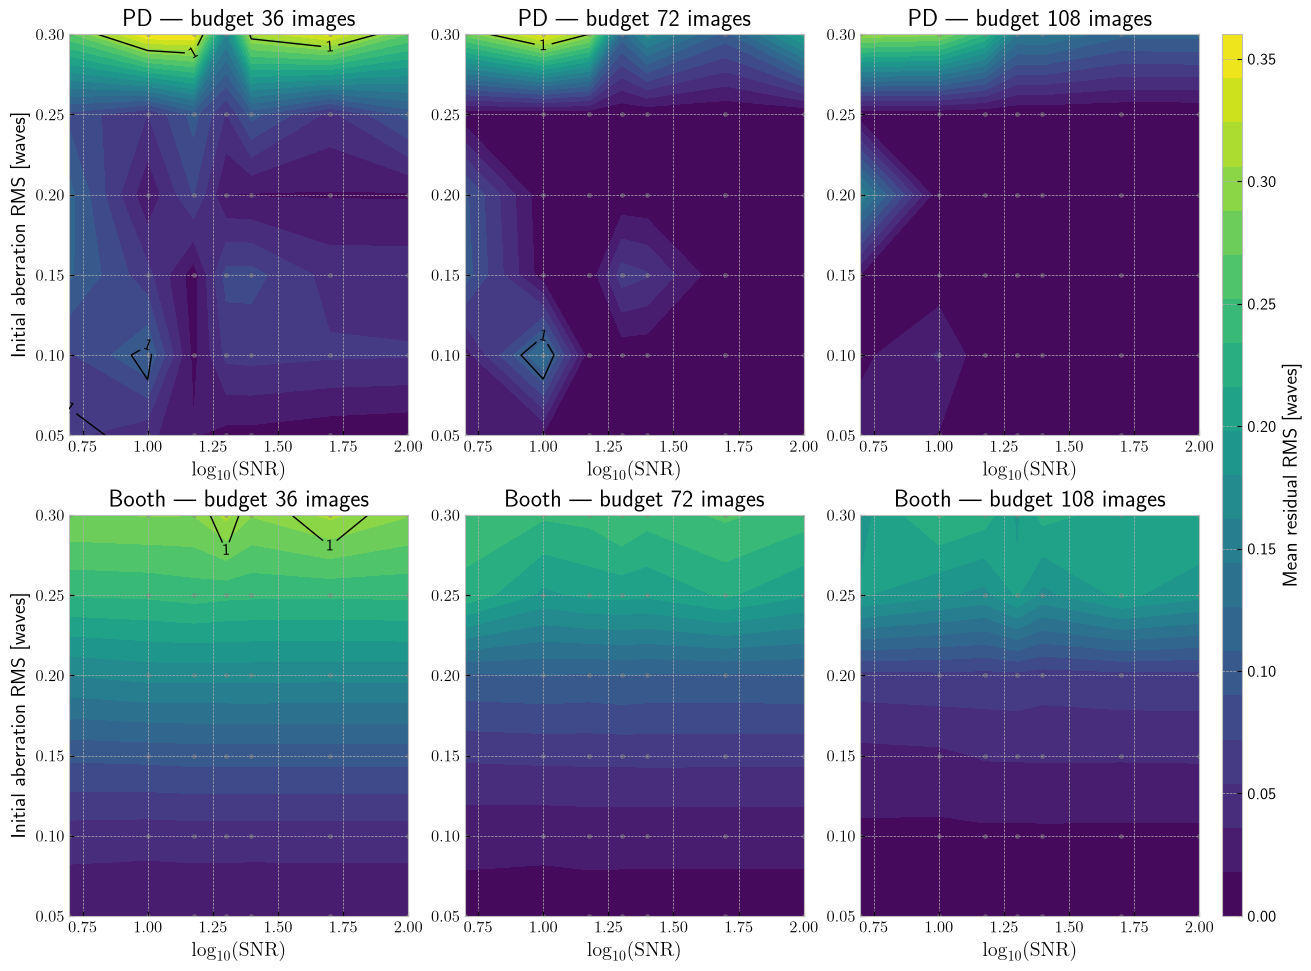

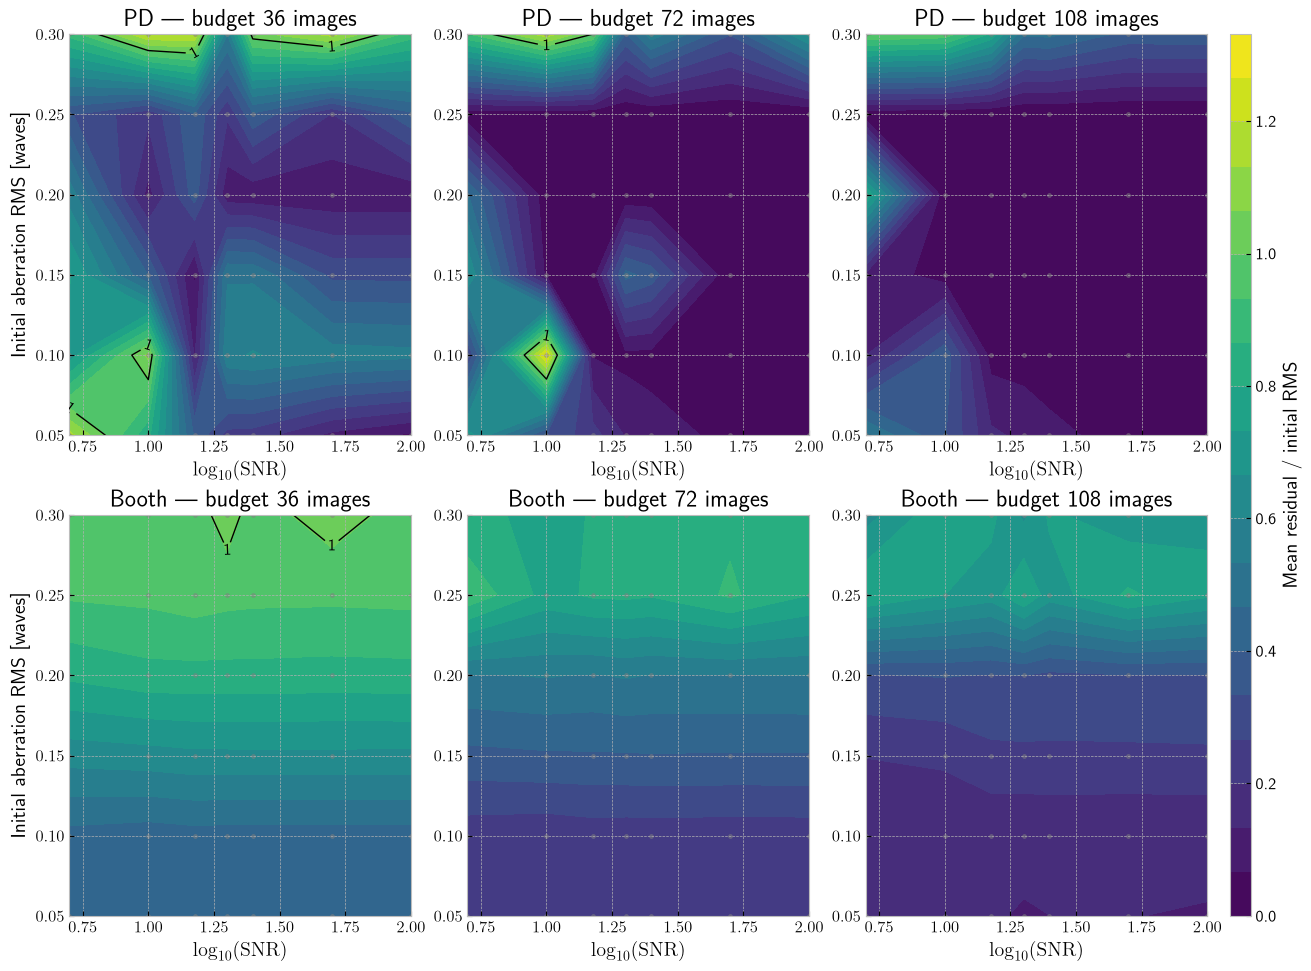

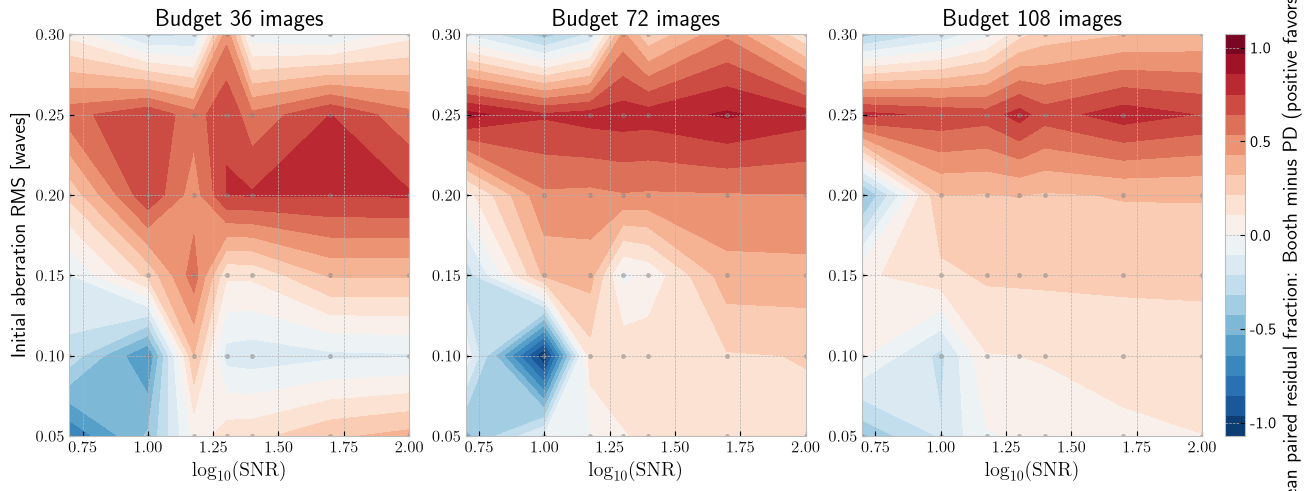

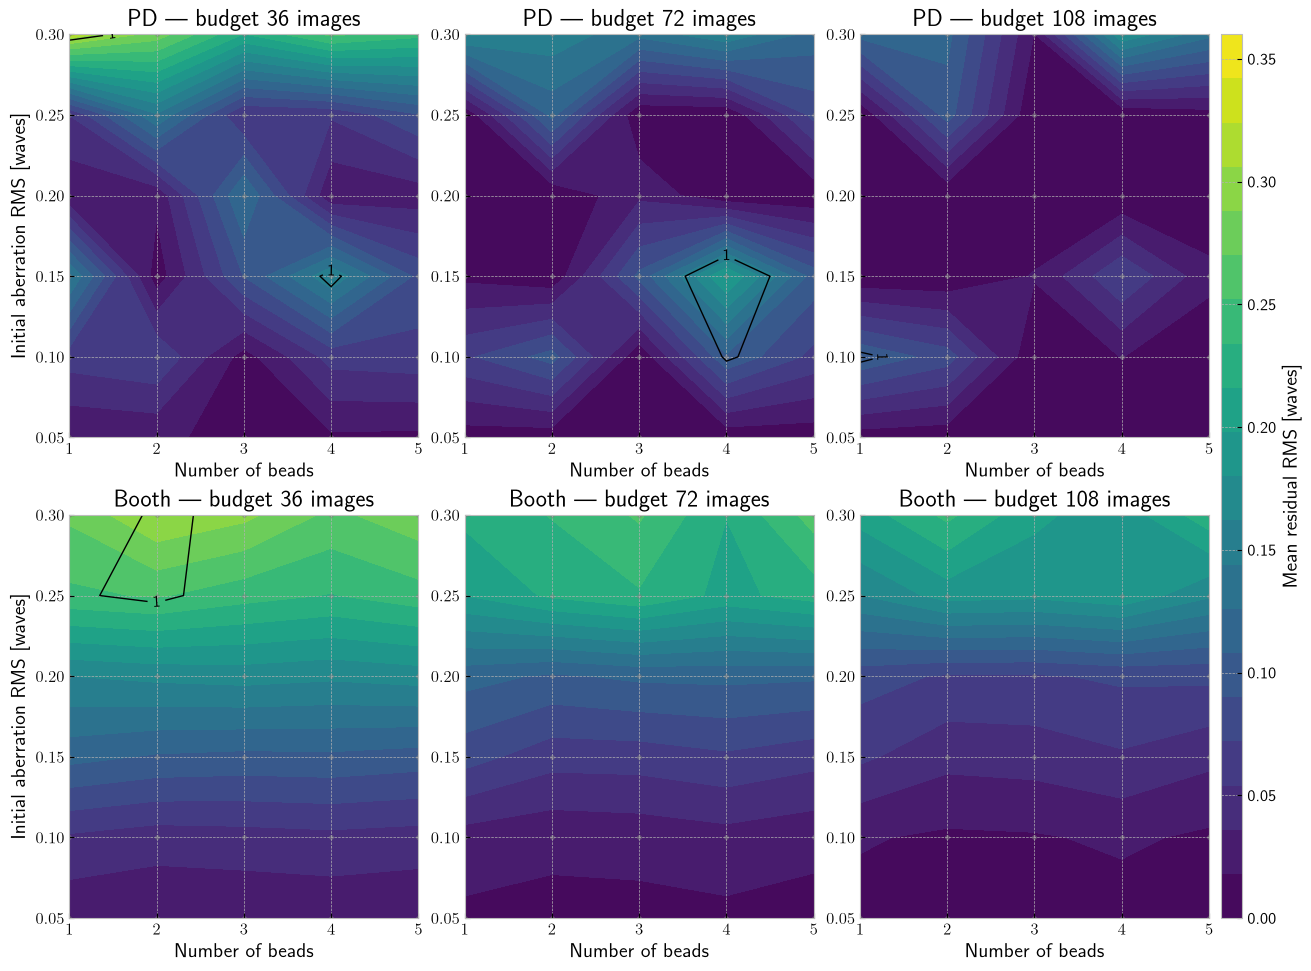

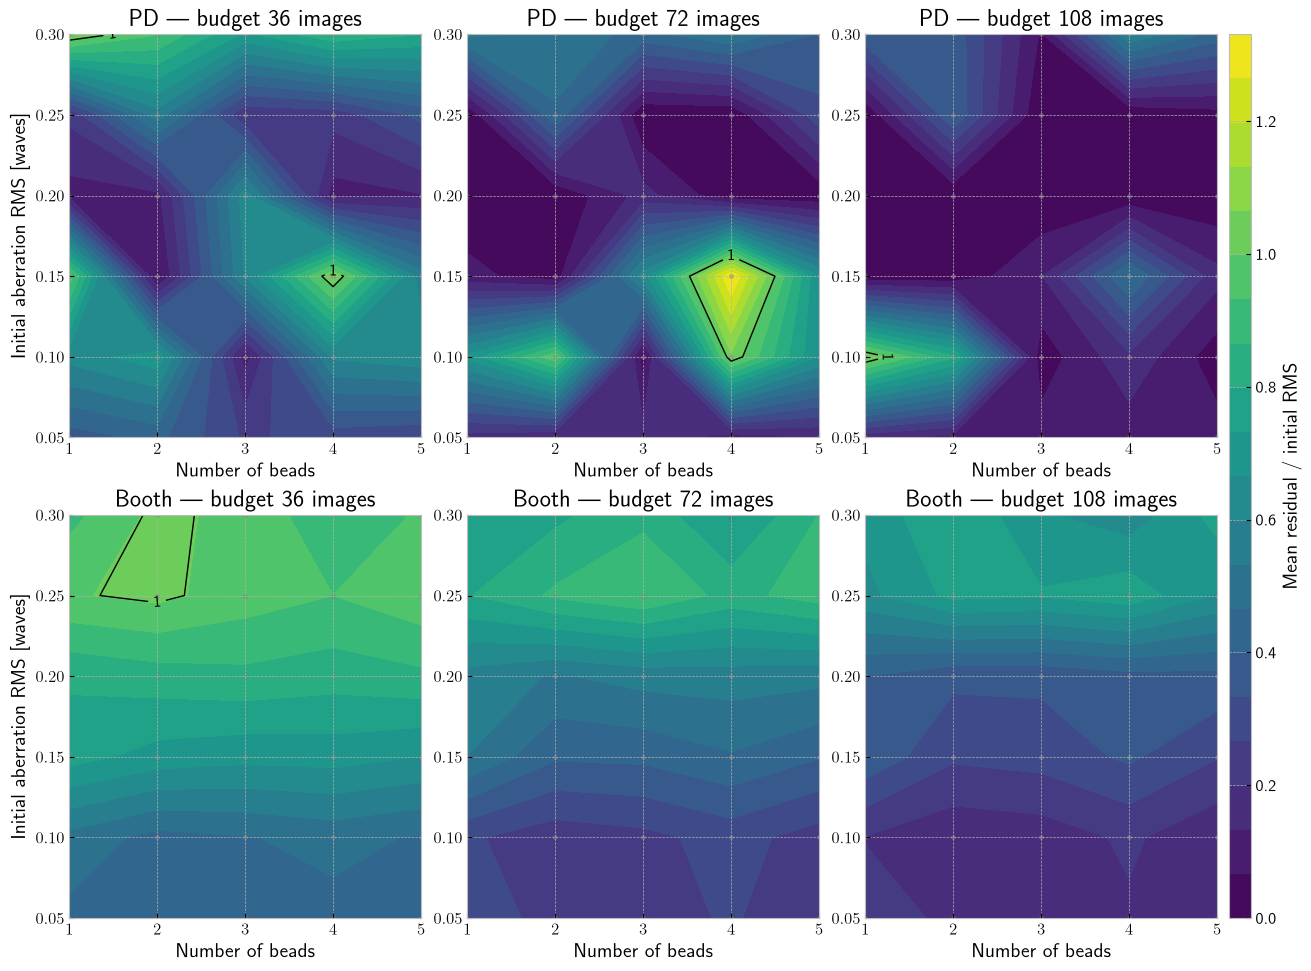

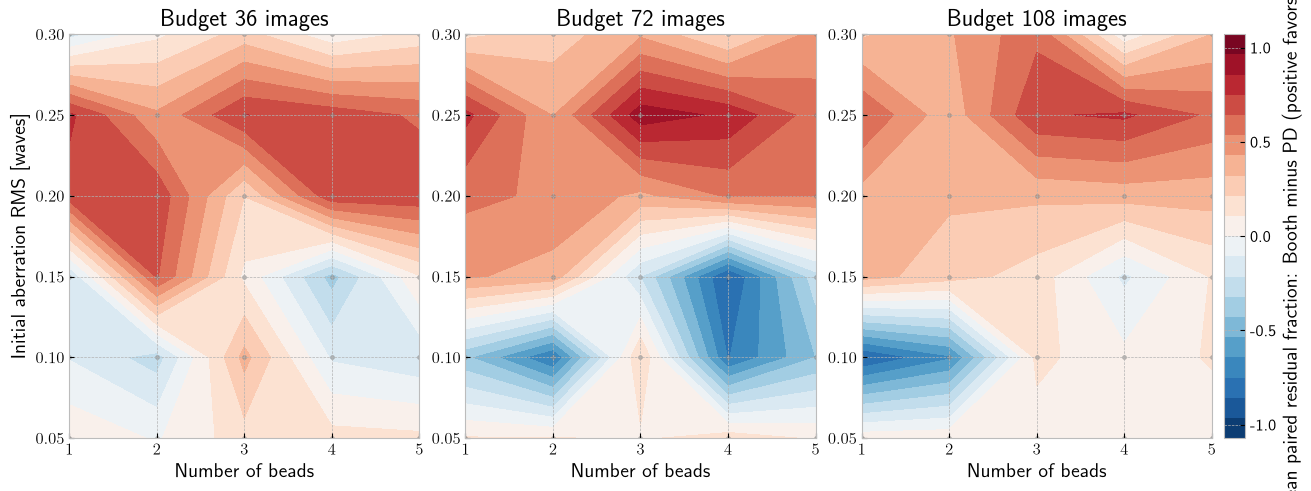

In [6]:
plot_comparisons(contour=True)


## Summary and checks

Report paired outcomes at each acquisition budget: mean and median residual RMS, number improving over the initial state, number below 0.01 waves, and how often PD has lower residual than Booth. Every trial contributes once; the three initial wavefront directions are reused across axes, so the case totals are not independent draws from a population of wavefronts. Mean-grid figures may conceal outliers; the archives retain every trial and every Booth correction/probe metric for later diagnosis.

In [7]:
summary = {}
for name,state in states.items():
    initial=state['initial_rms'][:,None,None]
    summary[name]={}
    for col,budget in enumerate(BUDGETS):
        pd=state['pd_residual_rms'][...,col]; booth=state['booth_residual_rms'][...,col]
        result={'cases':pd.size,'pd_lower_than_booth':int((pd<booth).sum()),'methods':{}}
        for method,values in [('PD',pd),('Booth',booth)]:
            result['methods'][method]=dict(mean_rms=float(values.mean()),median_rms=float(np.median(values)),
                improved=int((values<initial).sum()),below_0p01=int((values<.01).sum()))
        summary[name][str(budget)]=result
        print(name,budget,json.dumps(result))
with (RESULTS_DIR/'summary.json').open('w') as stream:
    json.dump(summary,stream,indent=2)
print('Result archives:', RESULTS_DIR)
print('Heatmaps:', FIGURES_DIR)

rms_snr 36 {"cases": 126, "pd_lower_than_booth": 89, "methods": {"PD": {"mean_rms": 0.09235301827116843, "median_rms": 0.04124965758857302, "improved": 105, "below_0p01": 28}, "Booth": {"mean_rms": 0.14354462476796145, "median_rms": 0.1238024477422481, "improved": 104, "below_0p01": 0}}}
rms_snr 72 {"cases": 126, "pd_lower_than_booth": 103, "methods": {"PD": {"mean_rms": 0.05061612697943321, "median_rms": 0.004142102831506372, "improved": 111, "below_0p01": 89}, "Booth": {"mean_rms": 0.10845077408842543, "median_rms": 0.07033717290448974, "improved": 124, "below_0p01": 8}}}
rms_snr 108 {"cases": 126, "pd_lower_than_booth": 102, "methods": {"PD": {"mean_rms": 0.040086236782022694, "median_rms": 0.002261847840701346, "improved": 117, "below_0p01": 102}, "Booth": {"mean_rms": 0.08746786656585015, "median_rms": 0.04791225124406187, "improved": 126, "below_0p01": 28}}}
bead_count 36 {"cases": 90, "pd_lower_than_booth": 69, "methods": {"PD": {"mean_rms": 0.09194688990511117, "median_rms": 0.

## Interpretation of this completed run

At the 108-image budget (Booth uses 105), PD has lower residual RMS in **102/126 RMS–SNR cases** and **79/90 bead-count cases**.

| Sweep | PD mean final RMS | Booth mean final RMS | PD below 0.01 waves | Booth below 0.01 waves |
|---|---:|---:|---:|---:|
| RMS–SNR | 0.04009 | 0.08747 | 102/126 | 28/126 |
| Bead count | 0.03444 | 0.08968 | 74/90 | 13/90 |

PD usually reaches much smaller residuals. However, Booth gives some net improvement in all 126 RMS–SNR cases and 88/90 bead-count cases, versus 117/126 and 83/90 for PD. Thus lower typical error and fewer harmful failures are distinct outcomes; neither should be hidden by the mean heatmaps.

Every paired initial scene passed the reference-SNR and initial wavefront-RMS checks. The saved Booth commands were independently checked to reproduce all 648 recorded residual RMS values; successive commands equal the saved updates, all modal updates respect the 0.10-wave limit, and image counts are exactly 35/70/105. Source PD data were not modified. All six heatmap figures are exported in both PNG and PDF.

These results apply to the fixed single-plane, simultaneous-update, 0.10-coefficient-wave Booth configuration and three wavefront directions. They do not establish that PD outperforms a separately tuned or differently sampled sensorless baseline.
